In [2]:
import matplotlib.pyplot as plt
import numpy as np

In [20]:
dictmap = lambda fn, ht: {x: fn(ht[x]) for x in ht.keys()}

def deriv_dict(ht):
    keys = list(ht.keys())
    return {keys[i]: (ht[keys[i+1]] - ht[keys[i]]) / (keys[i+1] - keys[i]) for i in range(len(keys) - 1)}

In [35]:
# group incast.

# random sau best, orice ai mai bun.
# FCT_gain_vs_def = dictmap(lambda x: x/100, {2: 9.69, 3: 13.85, 4: 13.0, 6: 10.39, 8: 8.86})

# aici doar best.
# FCT_gain_vs_rnd = dictmap(lambda x: x/100, {2: 6.38, 3: 4.25, 4: 1.91})

stds_away_def = {2: 0.9, 3: 11.4, 4: 34.3, 6: 130.6, 8: 289.0, 10: 548.4, 12: 914.8, 14: 1393.9, 16: 1946.7}
stds_away_def_deriv = deriv_dict(stds_away_def)

stds_away_bst = {2: 2.8, 3: 7.3, 4: 13.5, 6: 32.6, 8: 56.3, 10: 90.0, 12: 131.8, 14: 181.0, 16: 231.8}
stds_away_bst_deriv = deriv_dict(stds_away_bst)

h_bound = {h: 1/h for h in range(2, 15)}

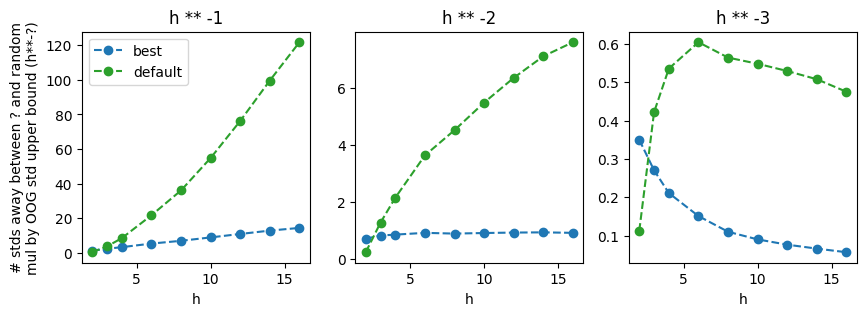

In [48]:
# titlu: # stds away between default/best and random, multiplied by OOG std upper bound (h**-1, h**-2, h**-3)
# we only have proof for h**-1, but decreasing FCT speedup against default suggests h**-2 bound.

fig, ax = plt.subplots(1, 3, figsize = (10, 3))

for i, exp in enumerate([1, 2, 3]):
    ax[i].plot(stds_away_bst.keys(), [stds_away_bst[h] / h ** exp for h in stds_away_bst.keys()], ls = "--", marker = 'o')
    ax[i].plot(stds_away_def.keys(), [stds_away_def[h] / h ** exp for h in stds_away_def.keys()], ls = "--", marker = 'o', c = "C2")
    
    ax[i].set_title(f"h ** -{exp}")
    
    ax[i].set_xlabel("h")
    if i == 0:
        ax[i].set_ylabel("# stds away between ? and random\nmul by OOG std upper bound (h**-?)")
        ax[i].legend(["best", "default"])

fig.savefig(
    "/home/vlad/Desktop/Probleme/LaburiDC/figs_implicit_asymmetry/cnt_stds_mul_oog_std_bound.pdf",
    bbox_inches = "tight"
)

In [ ]:
# scrie asa: we have an OOG std bound that converges to 0, but does it converge faster than the
# # stds away from mean converging to infinity?
# empirically (.. see fig), an O(1/h) bound is not enough. In order to observe
# decreasing FCT speedup against default, an O(1/h**2) bound may be plausible.